Código adaptado de:

[1] D. Foster, Generative Deep Learning: Teaching Machines to Paint, Write, Compose, and Play, Second Edition, O'Reilly, 2023.

[2] A. Géron, Hands-On Machine Learning with Scikit-Learning, Keras & Tensorflow, Third Edition, O'Reilly, 2022.

# Laboratório 8: Autoencoders Variacionais

## Importações

In [1]:
!pip install torchinfo

In [2]:
from __future__ import annotations                     # Permite anotações de tipos futuristas (self-referenciais)
from tqdm.auto import tqdm                             # Barra de progresso visual para loops (compatível com notebooks e terminal)
import matplotlib.pyplot as plt                        # Biblioteca para geração de gráficos e visualizações
import numpy as np                                     # Biblioteca para operações numéricas vetorizadas
import torch                                           # Biblioteca PyTorch
import torch.nn as nn                                  # Submódulo com classes de camadas neurais
import torch.nn.functional as F                        # Submódulo com funções úteis (ativação, perdas, etc.)
from scipy.stats import norm                           # Funções estatísticas (ex.: percentis e PDF da normal)
from torch.utils.data import DataLoader, TensorDataset # Gerenciador de mini-lotes de dados (facilita o treinamento)
from torchvision import datasets, transforms           # Conjuntos de dados e transformações de imagem do PyTorch
from torchinfo import summary                          # Sumário detalhado de modelos (tamanhos, parâmetros, shapes)

/Users/gilcesarf/git/repositories/imd/imd3004-202602/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configurações

In [3]:
# Define o dispositivo de hardware para execução: usa acelerador (GPU/TPU) se disponível; caso contrário, usa a CPU
DISPOSITIVO = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"

# Exibe qual dispositivo está sendo utilizado
print(f"Usando {DISPOSITIVO}.")

Usando mps.


## Hiperparâmetros

In [4]:
EPOCAS_DENSO            = 100   # @param {type:"integer"}   # Número total de épocas de treinamento
TAMANHO_LOTE_DENSO      = 128   # @param {type:"integer"}   # Tamanho do mini-lote (batch size)
DIMENSAO_LATENTE_DENSO  = 2     # @param {type:"integer"}   # Dimensionalidade do espaço latente z
BETA_DENSO              = 1     # @param {type:"number"}    # Peso do termo KL (β=1 -> VAE padrão)

## Dados

In [5]:
def carregar_dados_fashion_mnist(transformacao_imagem, tamanho_lote):

    # Carrega conjunto de treinamento (baixado automaticamente se não existir)
    train_data = datasets.FashionMNIST(
        root="data",
        train=True,
        transform=transformacao_imagem,
        download=True,
    )

    # Carrega conjunto de teste (baixado automaticamente se não existir)
    test_data = datasets.FashionMNIST(
        root="data",
        train=False,
        transform=transformacao_imagem,
        download=True,
    )

    # Cria DataLoaders (embaralha apenas o conjunto de treinamento)
    train_dl = DataLoader(train_data, batch_size=tamanho_lote, shuffle=True)
    test_dl = DataLoader(test_data, batch_size=tamanho_lote, shuffle=False)

    return train_dl, test_dl, len(train_data)

In [6]:
# Define a transformação das imagens (converte para tensor normalizado em [0,1])
transformacao_densa = transforms.ToTensor()

# Carrega os conjuntos de treinamento e teste do Fashion-MNIST com o tamanho de lote definido
train_dl, test_dl, _ = carregar_dados_fashion_mnist(transformacao_imagem=transformacao_densa, tamanho_lote=TAMANHO_LOTE_DENSO)

## Autoencoder variacional (denso)

### Rede Neural

#### Truque de reparametrização ($\mu + \sigma \cdot \varepsilon$)

In [7]:
class CamadaAmostragemLatente(nn.Module):
    """Implementa a amostragem reparametrizada z = μ + σ·ε com ε ~ N(0,I)."""

    def forward(self, media, log_variancia):
        """Gera uma amostra z a partir dos parâmetros da distribuição Gaussiana."""
        ruido_gaussiano = torch.randn_like(log_variancia)               # ε ~ N(0, 𝐈)
        desvio_padrao   = torch.exp(0.5 * log_variancia)                # σ = e^(logσ² / 2)
        vetor_latente   = media + desvio_padrao * ruido_gaussiano       # z = μ + σ·ε
        return vetor_latente

#### Codificador do VAE denso

In [8]:
class CodificadorDenso(nn.Module):
    """Codificador completamente conectado para imagens 28x28."""

    def __init__(self, dimensao_latente):
        super().__init__()

        # Bloco denso: flatten + camadas lineares + ativações não-lineares
        self.bloco_denso = nn.Sequential(
            nn.Flatten(),             # Achata a imagem 2D (1, 28, 28) → vetor de 784 elementos
            nn.Linear(28 * 28, 150),  # Primeira camada densa: 784 → 150 neurônios
            nn.ReLU(),                # Ativação ReLU 1
            nn.Linear(150, 100),      # Segunda camada densa: 150 → 100 neurônios
            nn.ReLU()                 # Ativação ReLU 2
        )

        # Cabeças de saída para μ e logσ²
        self.camada_media = nn.Linear(100, dimensao_latente)           # Gera vetor de médias μ ∈ R^DIMENSAO_LATENTE_DENSO
        self.camada_log_variancia = nn.Linear(100, dimensao_latente)   # Gera vetor de log-variâncias logσ² ∈ R^dim_latente
        self.camada_amostragem = CamadaAmostragemLatente()             # Reparametrização: z = μ + σ·ε

    def forward(self, imagens):
        """Propaga a imagem e retorna (μ, logσ², z)."""
        x = self.bloco_denso(imagens)                                  # Extrai características densas
        media = self.camada_media(x)                                   # Vetor de médias (μ)
        log_variancia = self.camada_log_variancia(x)                   # Vetor de log-variâncias (logσ²)
        vetor_latente = self.camada_amostragem(media, log_variancia)   # Amostra reparametrizada (z = μ + σ·ε)
        return media, log_variancia, vetor_latente

#### Decodificador do VAE denso

In [9]:
class DecodificadorDenso(nn.Module):
    """Decodificador completamente conectado."""

    def __init__(self, dimensao_latente):
        super().__init__()

        # Bloco denso: camadas lineares + ativações não-lineares
        self.bloco_denso = nn.Sequential(
            nn.Linear(dimensao_latente, 100),  # Entrada: vetor z → 100 neurônios
            nn.ReLU(),                         # Ativação ReLU 1
            nn.Linear(100, 150),               # Primeira camada densa: 100 → 150 neurônios
            nn.ReLU(),                         # Ativação ReLU 2
            nn.Linear(150, 28 * 28),           # Segunda camada densa: 150 → 784 (imagem achatada)
            nn.Sigmoid()                       # Garante saída ∈ (0, 1)
        )

    def forward(self, vetor_latente):
        """Reconstrói a imagem a partir do vetor latente z."""
        x = self.bloco_denso(vetor_latente)              # Passa pelo pipeline denso
        return x.view(-1, 1, 28, 28)                     # Reformata (B,784) → (B,1,28,28)

#### VAE

In [10]:
class AutoencoderVariacional(nn.Module):
    """Agrupa codificador e decodificador e calcula a função de perda MSE + β·KL."""

    def __init__(self, codificador, decodificador):
        super().__init__()
        self.codificador    = codificador                                   # Rede que gera (μ, logσ², z) a partir de x
        self.decodificador  = decodificador                                 # Rede que reconstrói x a partir de z

    def forward(self, imagens):
        """Codifica as imagens, amostra z e reconstrói as entradas."""
        media, log_variancia, vetor_latente = self.codificador(imagens)     # Passo 1: codificação x → (μ, logσ², z)
        reconstrucao = self.decodificador(vetor_latente)                    # Passo 2: decodificação (z → x̂)
        return reconstrucao, media, log_variancia

    @staticmethod
    def perda_mse_kl(reconstrucao, alvo, media, log_variancia, beta=1.0):
        """Calcula a perda total: erro de reconstrução (MSE) + regularização (β·KL)."""
        mse = F.mse_loss(reconstrucao, alvo, reduction="mean")                                  # Erro de reconstrução entre imagem original e reconstruída
        kl = -0.5 * torch.sum(1 + log_variancia - media.pow(2) - log_variancia.exp(), dim=1)    # Termo KL: mede o afastamento entre q(z|x) = N(μ,σ²) (aprendida pelo codificador) e a distribuição a priori p(z)=N(0,1) (assumida na modelagem)
        kl = kl.mean() / (alvo.size(2) * alvo.size(3))                                          # Normaliza por pixel (HxW) para manter mesma escala do MSE
        perda_total = mse + beta * kl                                                           # Combina termos: total = MSE + β·KL
        return perda_total, mse.detach(), kl.detach()                                           # Detach: impede retropropagação nos logs

In [11]:
# Instancia o VAE denso
vae_denso = AutoencoderVariacional(
    CodificadorDenso(DIMENSAO_LATENTE_DENSO),
    DecodificadorDenso(DIMENSAO_LATENTE_DENSO),
).to(DISPOSITIVO)

In [12]:
# Inspecionar modelo
summary(vae_denso, input_size=(1, 1, 28, 28), col_names=["input_size", "output_size", "num_params"], device=DISPOSITIVO) # mostra resumo do VAE

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
AutoencoderVariacional                   [1, 1, 28, 28]            [1, 1, 28, 28]            --
├─CodificadorDenso: 1-1                  [1, 1, 28, 28]            [1, 2]                    --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 100]                  --
│    │    └─Flatten: 3-1                 [1, 1, 28, 28]            [1, 784]                  --
│    │    └─Linear: 3-2                  [1, 784]                  [1, 150]                  117,750
│    │    └─ReLU: 3-3                    [1, 150]                  [1, 150]                  --
│    │    └─Linear: 3-4                  [1, 150]                  [1, 100]                  15,100
│    │    └─ReLU: 3-5                    [1, 100]                  [1, 100]                  --
│    └─Linear: 2-2                       [1, 100]                  [1, 2]                    202
│    └─Linear: 2-3       

## Treinamento

In [13]:
def treinar_vae(modelo, carregador_treino, epocas, otimizador, beta, nome_tag):

    tamanho_conjunto = len(carregador_treino.dataset)                                   # Número total de amostras no conjunto de treinamento
    historico_perda, historico_mse, historico_kl = [], [], []                           # Listas para armazenar o histórico de métricas por época
    progress_bar = tqdm(range(1, epocas + 1), desc=f"[{nome_tag}] Épocas")   # Barra de progresso visual para acompanhar o treinamento

    # Loop principal sobre as épocas
    for _ in progress_bar:
        modelo.train()                                       # Ativa modo de treinamento (dropout, BN, etc.)
        soma_perda = 0.0                                     # Acumulador de perda total
        soma_mse = 0.0                                       # Acumulador do erro de reconstrução
        soma_kl = 0.0                                        # Acumulador do termo de regularização KL

        # Loop interno sobre os mini-lotes de treinamento
        for imagens, _ in carregador_treino:
            imagens = imagens.to(DISPOSITIVO)                                                                           # Move o lote para GPU ou CPU
            otimizador.zero_grad()                                                                                      # Zera gradientes acumulados
            reconstrucao, media, log_variancia = modelo(imagens)                                                        # Forward pass: x → (μ, logσ², z) → x̂
            perda, mse, kl = AutoencoderVariacional.perda_mse_kl(reconstrucao, imagens, media, log_variancia, beta)     # Calcula perda total e seus componentes
            perda.backward()                                                                                            # Retropropaga os gradientes
            otimizador.step()                                                                                           # Atualiza os parâmetros da rede

            # Acumula perdas ponderadas pelo tamanho do mini-lote
            soma_perda += perda.item() * imagens.size(0)
            soma_mse   += mse.item() * imagens.size(0)
            soma_kl    += kl.item() * imagens.size(0)

        # Calcula médias ponderadas das métricas por época
        perda_media = soma_perda / tamanho_conjunto
        mse_media   = soma_mse / tamanho_conjunto
        kl_media    = soma_kl / tamanho_conjunto

        # Armazena histórico
        historico_perda.append(perda_media)
        historico_mse.append(mse_media)
        historico_kl.append(kl_media)

        # Atualiza a barra de progresso com as métricas atuais
        progress_bar.set_postfix({
            "Perda": f"{perda_media:.5f}",
            "MSE": f"{mse_media:.5f}",
            "KL": f"{kl_media:.5f}"
        })

    # Retorna as curvas de perda, MSE e KL por época
    return historico_perda, historico_mse, historico_kl

In [14]:
def curvas_de_treinamento(loss_hist, mse_hist, kl_hist):
    """Plota as curvas de perda, MSE e KL ao longo das épocas."""
    plt.figure()                                    # Cria a figura e define o tamanho
    plt.plot(loss_hist, label="Função de perda")    # Curva da perda total
    plt.plot(mse_hist, label="MSE")                 # Curva do erro de reconstrução
    plt.plot(kl_hist, label="KL")                   # Curva do termo de regularização
    plt.xlabel("Época")                             # Define o rótulo do eixo X
    plt.legend()                                    # Exibe a legenda das curvas
    plt.grid(True)                                  # Adiciona grade ao gráfico
    plt.tight_layout()                              # Ajusta margens automaticamente
    plt.show()                                      # Exibe o gráfico na tela

In [15]:
otimizador_denso = torch.optim.Adam(vae_denso.parameters(), lr=1e-3) # define otimizador

In [16]:
hist_loss, hist_mse, hist_kl = treinar_vae(
    modelo=vae_denso,
    carregador_treino=train_dl,
    epocas=EPOCAS_DENSO,
    otimizador=otimizador_denso,
    beta=BETA_DENSO,
    nome_tag="DENSO",
)

[DENSO] Épocas: 100%|██████████| 100/100 [04:52<00:00,  2.93s/it, Perda=0.03239, MSE=0.02551, KL=0.00688]


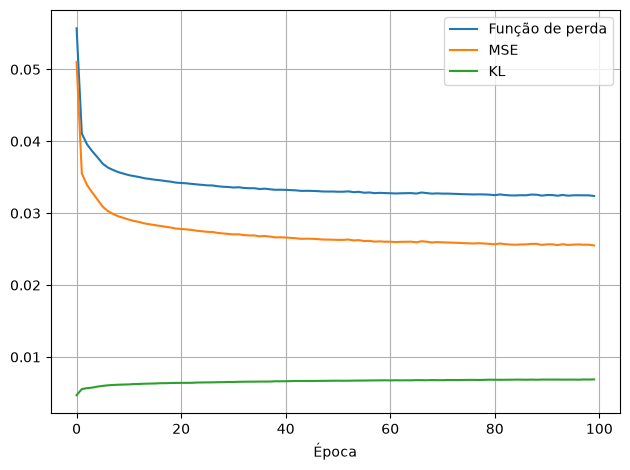

In [17]:
curvas_de_treinamento(hist_loss, hist_mse, hist_kl)

## Visualizações

In [18]:
def mostrar_reconstrucoes(modelo, carregador_teste, quantidade_imagens):
    """Exibe imagens originais e respectivas reconstruções lado a lado."""

    modelo.eval()                                          # Coloca o modelo em modo de avaliação (desativa dropout, BN, etc.)
    imagens, _ = next(iter(carregador_teste))              # Obtém um único mini-lote do conjunto de teste
    imagens = imagens.to(DISPOSITIVO)[:quantidade_imagens] # Seleciona as N primeiras imagens e move para GPU/CPU

    with torch.no_grad():                                  # Desativa o cálculo de gradientes
        reconstrucoes, _, _ = modelo(imagens)              # Passa as imagens pelo VAE → obtém reconstruções

    plt.figure(figsize=(quantidade_imagens * 1.5, 3))      # Define tamanho da figura de forma proporcional ao número de imagens

    for indice in range(quantidade_imagens):

        # Linha superior: imagens originais
        plt.subplot(2, quantidade_imagens, indice + 1)
        plt.imshow(imagens[indice].cpu().squeeze(), cmap="binary")          # Exibe imagem real (convertida para CPU)
        plt.axis("off")                                                     # Remove eixos

        # Linha inferior: imagens reconstruídas
        plt.subplot(2, quantidade_imagens, quantidade_imagens + indice + 1)
        plt.imshow(reconstrucoes[indice].cpu().squeeze(), cmap="binary")    # Exibe reconstrução correspondente
        plt.axis("off")                                                     # Remove eixos

    plt.tight_layout()                                     # Ajusta espaçamento automaticamente
    plt.show()                                             # Exibe a figura

In [19]:
def gerar_amostras_aleatorias(modelo, dimensao_latente, total_imagens, colunas):
    """Gera novas amostras a partir de vetores latentes aleatórios (z ~ N(0,1))."""

    modelo.eval()                                                                           # Coloca o modelo em modo de avaliação
    with torch.no_grad():                                                                   # Desativa o cálculo de gradientes
        vetores_latentes = torch.randn(total_imagens, dimensao_latente, device=DISPOSITIVO) # Gera vetores latentes amostrados da distribuição padrão N(0,1)
        imagens = modelo.decodificador(vetores_latentes).cpu().numpy()                      # Decodifica os vetores latentes em imagens sintéticas

    linhas = (total_imagens - 1) // colunas + 1             # Calcula o número de linhas necessárias para organizar as imagens na grade
    plt.figure(figsize=(colunas, linhas))                   # Define tamanho proporcional da figura

    # Exibe cada imagem na grade (linhas x colunas)
    for indice, imagem in enumerate(imagens):
        plt.subplot(linhas, colunas, indice + 1)            # Define posição do subplot
        plt.imshow(imagem.squeeze(), cmap="binary")         # Exibe imagem (remove canal e usa tons de cinza)
        plt.axis("off")                                     # Remove eixos para visualização limpa
    plt.tight_layout()                                      # Ajusta margens automaticamente
    plt.show()                                              # Exibe a figura

In [20]:
def visualizar_espaco_latente(modelo, carregador_dados, nome_figura="espaco_latente.png"):
    """Projeta os vetores de médias μ no espaço latente 2D, colorindo cada ponto pela classe, e desenha o contorno com 99% da massa da priori N(0, I)."""

    modelo.eval()                                         # Coloca o modelo em modo de avaliação (sem dropout, BN, etc.)
    vetores_latentes = []                                 # Lista para armazenar os vetores μ de cada amostra
    rotulos = []                                          # Lista para armazenar os rótulos correspondentes

    with torch.no_grad():                                 # Desativa o cálculo de gradientes

        for imagens, y in carregador_dados:               # Itera sobre todo o conjunto de dados
            imagens = imagens.to(DISPOSITIVO)             # Move lote para GPU/CPU
            media, _, _ = modelo.codificador(imagens)     # Extrai o vetor μ de cada imagem
            vetores_latentes.append(media.cpu().numpy())  # Move para CPU e converte em numpy
            rotulos.append(y.numpy())                     # Armazena rótulos das classes

    # Concatena todos os vetores μ e rótulos em arrays únicos
    pontos_z = np.concatenate(vetores_latentes)
    classes  = np.concatenate(rotulos)

    plt.figure(figsize=(8, 6))                                                                      # Define o tamanho da figura
    grafico = plt.scatter(pontos_z[:, 0], pontos_z[:, 1], c=classes, cmap="tab10", s=10, alpha=0.7) # Cria o gráfico de dispersão dos pontos latentes coloridos por classe
    raio_99 = np.sqrt(-2 * np.log(1 - 0.99))                                                        # Raio do círculo com 99% da massa de N(0, I) em 2D (||z||² segue uma qui-quadrado com 2 graus de liberdade)
    angulos = np.linspace(0, 2 * np.pi, 200)                                                        # Ângulos para traçar o círculo
    plt.plot(raio_99 * np.cos(angulos), raio_99 * np.sin(angulos), "k--", label=r"$99$% de $\mathcal{N}(0, I)$")   # Desenha o contorno tracejado da priori
    plt.gca().set_aspect("equal", adjustable="datalim")                                             # Usa a mesma escala nos dois eixos, para o círculo não virar elipse
    plt.legend(loc="upper right")                                                                   # Adiciona a legenda do contorno
    plt.colorbar(grafico, ticks=range(10), label="Classe")                                          # Adiciona barra de cores indicando as classes
    plt.title(r"Projeção de $\mu$ no espaço latente (2D)")                                          # Título do gráfico
    plt.xlabel("z[0]")                                                                              # Eixo horizontal: primeira dimensão latente
    plt.ylabel("z[1]")                                                                              # Eixo vertical: segunda dimensão latente
    plt.grid(True)                                                                                  # Adiciona grade para melhor visualização
    plt.tight_layout()                                                                              # Ajusta margens automaticamente
    plt.show()                                                                                      # Exibe o gráfico

In [21]:
def visualizar_grade_latente(decodificador, tamanho_grade=20):
    """Gera uma grade de imagens decodificadas a partir de pontos regulares no espaço latente 2D."""

    assert tamanho_grade > 1, "Tamanho da grade deve ser maior que 1."   # Garante que a grade tenha pelo menos 2 pontos por eixo

    # Gera coordenadas no espaço latente com base nos percentis da Normal padrão N(0,1)
    # Usar percentis evita pontos extremos (muito afastados da densidade central)
    eixo = norm.ppf(np.linspace(0.01, 0.99, tamanho_grade))

    linhas_imagem = []                                                   # Lista para armazenar linhas da grade de imagens
    for valor_y in eixo:                                                 # Varre o eixo vertical (dimensão z[1])
        linha_atual = []                                                 # Armazena as imagens de uma linha da grade
        for valor_x in eixo:                                             # Varre o eixo horizontal (dimensão z[0])
            # Cria o vetor latente z = [valor_x, valor_y]
            ponto_latente = torch.tensor([[valor_x, valor_y]], dtype=torch.float32, device=DISPOSITIVO)
            # Decodifica o ponto latente em uma imagem (sem gradientes)
            with torch.no_grad():
                imagem = decodificador(ponto_latente).cpu().squeeze().numpy()
            linha_atual.append(imagem)                                   # Adiciona imagem à linha atual
        # Concatena horizontalmente as imagens da linha
        linhas_imagem.append(np.concatenate(linha_atual, axis=1))

    # Concatena todas as linhas verticalmente -> imagem completa da grade
    imagem_grade = np.concatenate(linhas_imagem, axis=0)

    plt.figure(figsize=(8, 8))                                           # Define tamanho da figura
    plt.imshow(imagem_grade, cmap="binary")                              # Exibe imagem composta em escala de cinza
    plt.axis("off")                                                      # Remove eixos para visualização limpa
    plt.title("Reconstruções em grade no espaço latente 2D")             # Título do gráfico
    plt.tight_layout()                                                   # Ajusta margens automaticamente
    plt.show()                                                           # Exibe a figura

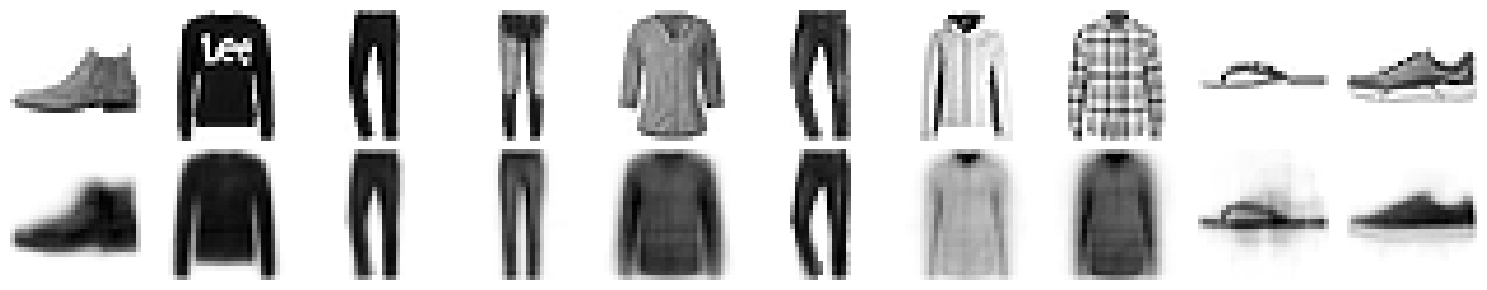

In [22]:
mostrar_reconstrucoes(vae_denso, test_dl, quantidade_imagens=10)

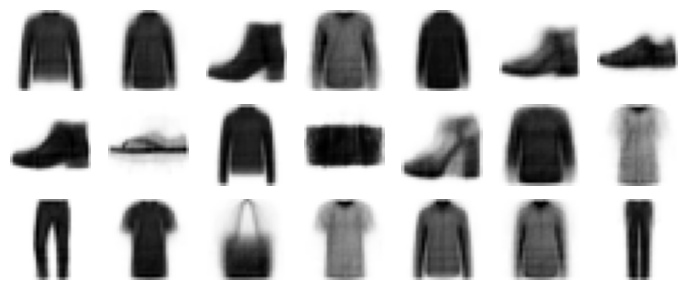

In [23]:
gerar_amostras_aleatorias(vae_denso, DIMENSAO_LATENTE_DENSO, total_imagens=21, colunas=7)

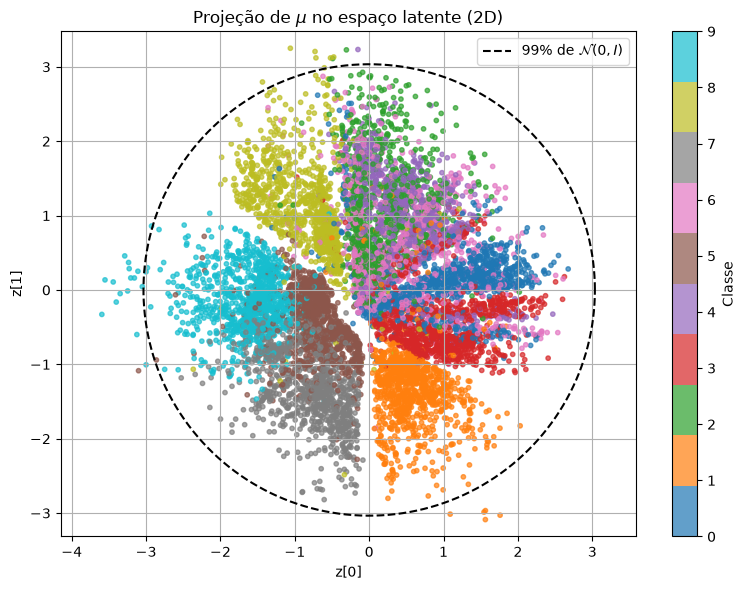

In [24]:
visualizar_espaco_latente(vae_denso, test_dl)

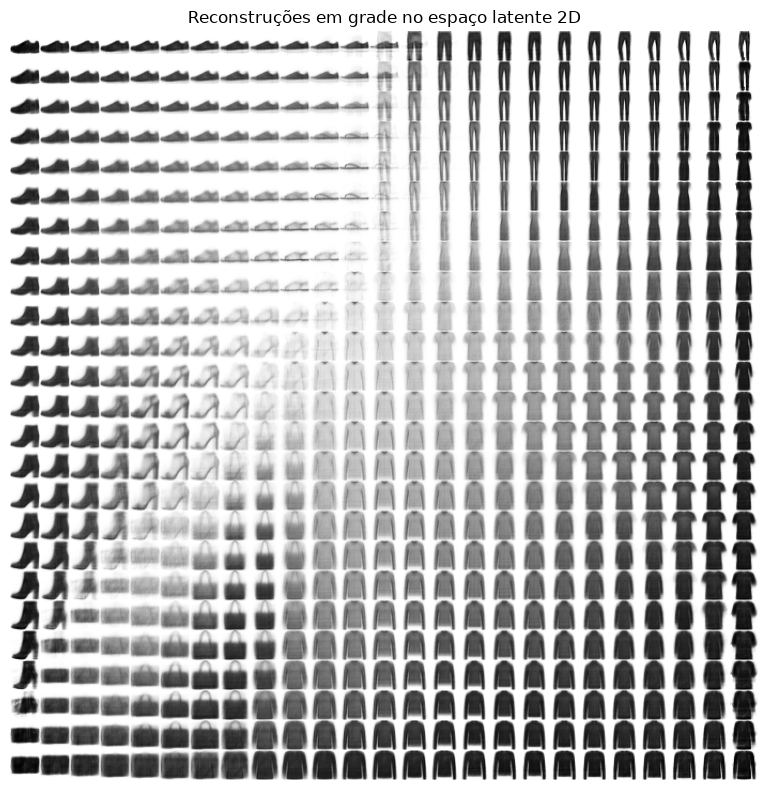

In [25]:
visualizar_grade_latente(vae_denso.decodificador, tamanho_grade=25)

# Tarefa (em duplas)

**Implementar um autoencoder variacional (VAE) convolucional, treiná-lo com a base de dados MNIST e investigar o efeito do peso $\beta$ do termo de regularização (KL) nas reconstruções, no espaço latente e nas amostras geradas**

Utilize o código acima como base e adapte-o conforme os itens a seguir, organizados em quatro etapas: preparação, experimentos, resultados e análise. Não apague nem reordene as células de enunciado; responda abaixo de cada **Resposta**, usando quantas células precisar.

**Observação:** para que os experimentos sejam comparáveis, treine todos com a mesma arquitetura convolucional, por 10 épocas, com lotes de 128 imagens, espaço latente de dimensão 2 (os valores de `EPOCAS_DENSO`, `TAMANHO_LOTE_DENSO` e `DIMENSAO_LATENTE_DENSO` no código do laboratório), o mesmo otimizador (`Adam` com `lr=1e-3`) e a mesma semente aleatória (`torch.manual_seed(42)` imediatamente antes de instanciar cada modelo). Altere apenas o valor de $\beta$.

**Entregáveis:**

Ao final da Unidade 2, você entregará **o notebook de cada laboratório da unidade**,
um arquivo `.ipynb` por laboratório, com a tarefa respondida ao final.

Cada notebook deve **executar do início ao fim sem erros**, em um kernel novo,
com *Restart & Run All*. Antes de entregar, execute-o dessa forma e confirme
que todas as células rodam na ordem em que aparecem e que as saídas exibidas
correspondem a essa execução. Notebooks que não executarem por completo serão
penalizados.

A entrega é **única por grupo**. Identifique os integrantes no início de cada
notebook.

## Preparação

### 1. Conjunto MNIST

Substitua o conjunto *Fashion-MNIST* pelo conjunto de dígitos *MNIST*, disponível em [`torchvision.datasets`](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST). Para isso, crie a função `carregar_dados_mnist`, igual a `carregar_dados_fashion_mnist` exceto pelas linhas que carregam os conjuntos:

```python
train_data = datasets.MNIST(root="data", train=True, transform=transformacao_imagem, download=True)    # carrega conjunto de treinamento
test_data  = datasets.MNIST(root="data", train=False, transform=transformacao_imagem, download=True)   # carrega conjunto de teste
```

Use-a para recriar `train_dl` e `test_dl` com `transformacao_densa` e `TAMANHO_LOTE_DENSO`, e mostre algumas imagens de um lote de `train_dl`.

Obs.: mantenha `transforms.ToTensor()` como transformação, sem normalizar para [-1, 1]: as imagens precisam ficar em [0, 1], o intervalo de saída da `nn.Sigmoid` do decodificador, pois o MSE de `perda_mse_kl` compara a reconstrução diretamente com a imagem de entrada.

#### Resposta

In [26]:
def carregar_dados_mnist(transformacao_imagem, tamanho_lote):

    # Carrega conjunto de treinamento (baixado automaticamente se não existir)
    train_data = datasets.MNIST(
        root="data",
        train=True,
        transform=transformacao_imagem,
        download=True,
    )

    # Carrega conjunto de teste (baixado automaticamente se não existir)
    test_data = datasets.MNIST(
        root="data",
        train=False,
        transform=transformacao_imagem,
        download=True,
    )

    # Cria DataLoaders (embaralha apenas o conjunto de treinamento)
    train_dl = DataLoader(train_data, batch_size=tamanho_lote, shuffle=True)
    test_dl = DataLoader(test_data, batch_size=tamanho_lote, shuffle=False)

    return train_dl, test_dl, len(train_data)

In [27]:
train_dl, test_dl, _ = carregar_dados_mnist(transformacao_densa, TAMANHO_LOTE_DENSO)

print(f'train_dl shape: {next(iter(train_dl))[0].shape}')
print(f'test_dl shape: {next(iter(test_dl))[0].shape}')

print(f'train_data shape: {train_dl.dataset.data.shape}')
print(f'test_data shape: {test_dl.dataset.data.shape}')

train_dl shape: torch.Size([128, 1, 28, 28])
test_dl shape: torch.Size([128, 1, 28, 28])
train_data shape: torch.Size([60000, 28, 28])
test_data shape: torch.Size([10000, 28, 28])


In [28]:
# plota imagens originais
def plot_samples_from_dataloader(dataloader, n_images=10):
    fig = plt.figure(figsize=(n_images * 1.5, 3))        # cria figura

    i = 0                                                # inicializa contador de imagens amostradas
    categorias = set()                                   # armazena as categorias já apresentadas

    for X, y in dataloader:                              # iterar sobre o dataloader
        for image, label in zip(X, y):                   # iterar sobre as imagens do lote
            if i >= n_images:                            # verifiqua se ja amostramos n_images
                break

            label = label.item()

            if label in categorias:                      # se a categoria ja foi amostrada,
                continue                                 # busca o proximo item

            plt.subplot(1, n_images, i + 1)              # subplot imagem original
            plt.imshow(image.squeeze(0), cmap="binary")  # exibe imagem original
            plt.title(f"Label: {label}")                 # exibe rótulo da imagem
            plt.axis("off")                              # oculta eixos

            categorias.add(label)                        # armazena categoria amostrada
            i += 1                                       # incrementa contador de imagens

            if len(categorias) == 10:
                categorias.clear()                       # reinicia controle das categorias

        if i >= n_images:                                # verifiqua se ja amostramos n_images
            break

    plt.show()  # Exibe o resultado final

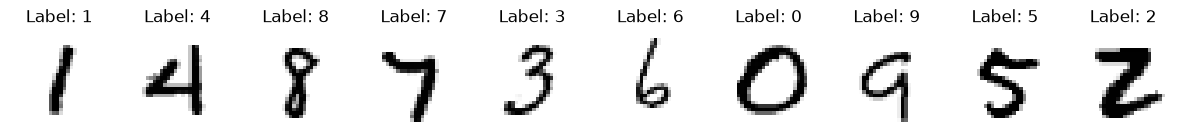

In [29]:
plot_samples_from_dataloader(train_dl)

### 2. VAE convolucional

Implemente as classes `CodificadorConvolucional` e `DecodificadorConvolucional`, versões convolucionais de `CodificadorDenso` e `DecodificadorDenso` que recebem `dimensao_latente` no construtor e mantêm a mesma interface, de modo que possam ser combinadas em `AutoencoderVariacional` sem alterar `perda_mse_kl` nem `treinar_vae`:

- `CodificadorConvolucional` recebe imagens de *shape* `(B, 1, 28, 28)`, extrai características com camadas `nn.Conv2d` e, a partir delas, calcula `media` e `log_variancia` com duas cabeças `nn.Linear` e `vetor_latente` com `CamadaAmostragemLatente`, retornando `(media, log_variancia, vetor_latente)`;
- `DecodificadorConvolucional` recebe `vetor_latente`, de *shape* `(B, dimensao_latente)`, projeta-o com uma `nn.Linear` em mapas de características e os amplia com camadas `nn.ConvTranspose2d` até `(B, 1, 28, 28)`, terminando em `nn.Sigmoid`, como `DecodificadorDenso`.

Você pode partir de `ConvEncoder` e `ConvDecoder` do Laboratório 7. Confira os *shapes* com `summary`, como no código do laboratório:

```python
vae_conv = AutoencoderVariacional(
  CodificadorConvolucional(DIMENSAO_LATENTE_DENSO), 
  DecodificadorConvolucional(DIMENSAO_LATENTE_DENSO)
).to(DISPOSITIVO)
summary(vae_conv, input_size=(1, 1, 28, 28), col_names=["input_size", "output_size", "num_params"])  # a saída deve ter shape [1, 1, 28, 28]
```

Obs.: o decodificador deve retornar `(B, 1, 28, 28)`, o mesmo *shape* das imagens de entrada, e não `(B, 28, 28)`, como `ConvDecoder` do Laboratório 7.

#### Resposta

In [46]:
class CodificadorConvolucional(nn.Module):
    """Codificador convolucional para imagens 28x28."""

    def __init__(self, dimensao_latente):
        super().__init__()

        # Bloco convolucional: extrai características das imagens
        self.bloco_convolucional = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.AdaptiveAvgPool2d(output_size=(1, 1)),
            nn.Flatten()
        )

        # Cabeças de saída para μ e logσ²
        self.camada_media = nn.Linear(64, dimensao_latente)
        self.camada_log_variancia = nn.Linear(64, dimensao_latente)
        self.camada_amostragem = CamadaAmostragemLatente()

    def forward(self, imagens):
        """Propaga a imagem e retorna (μ, logσ², z)."""
        x = self.bloco_convolucional(imagens)                    # Extrai características -> (B, 64)
        media = self.camada_media(x)                            # Vetor de médias -> (B, dimensao_latente)
        log_variancia = self.camada_log_variancia(x)            # Vetor de log-variâncias -> (B, dimensao_latente)
        vetor_latente = self.camada_amostragem(media, log_variancia)

        return media, log_variancia, vetor_latente

In [47]:
class DecodificadorConvolucional(nn.Module):
    """Decodificador convolucional para imagens 28x28."""

    def __init__(self, dimensao_latente):
        super().__init__()

        # Projeta o vetor latente em 16 mapas de características 3x3
        self.fc = nn.Linear(
            in_features=dimensao_latente,
            out_features=3 * 3 * 16
        )

        # Bloco convolucional: amplia os mapas de 3x3 até 28x28
        self.bloco_convolucional = nn.Sequential(
            nn.ConvTranspose2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                stride=2
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                in_channels=32,
                out_channels=16,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                in_channels=16,
                out_channels=1,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, vetor_latente):
        """Reconstrói a imagem a partir do vetor latente z."""
        x = self.fc(vetor_latente)             # Projeta z em 144 características
        x = x.view(-1, 16, 3, 3)               # Remodela para (B, 16, 3, 3)
        return self.bloco_convolucional(x)     # Reconstrói (B, 1, 28, 28)

In [48]:
# Instancia o VAE convolucional
vae_conv = AutoencoderVariacional(
    CodificadorConvolucional(DIMENSAO_LATENTE_DENSO),
    DecodificadorConvolucional(DIMENSAO_LATENTE_DENSO),
).to(DISPOSITIVO)

In [49]:
summary(vae_conv,                                   # mostra resumo da rede
        input_size=(1, 1, 28, 28),
        col_names=(
            "input_size", 
            "output_size", 
            "num_params"), 
        device=DISPOSITIVO)                             # adiciona device=device para nao tirar o modelo da gpu

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
AutoencoderVariacional                   [1, 1, 28, 28]            [1, 1, 28, 28]            --
├─CodificadorConvolucional: 1-1          [1, 1, 28, 28]            [1, 2]                    --
│    └─Sequential: 2-1                   [1, 1, 28, 28]            [1, 64]                   --
│    │    └─Conv2d: 3-1                  [1, 1, 28, 28]            [1, 16, 28, 28]           160
│    │    └─ReLU: 3-2                    [1, 16, 28, 28]           [1, 16, 28, 28]           --
│    │    └─MaxPool2d: 3-3               [1, 16, 28, 28]           [1, 16, 14, 14]           --
│    │    └─Conv2d: 3-4                  [1, 16, 14, 14]           [1, 32, 14, 14]           4,640
│    │    └─ReLU: 3-5                    [1, 32, 14, 14]           [1, 32, 14, 14]           --
│    │    └─MaxPool2d: 3-6               [1, 32, 14, 14]           [1, 32, 7, 7]             --
│    │    └─Conv2d: 3-7        

## Experimentos

### 3. Treinamento dos quatro experimentos

Treine o VAE convolucional com quatro valores do peso do termo KL, $\beta \in \{0, 0.1, 1, 100\}$, totalizando quatro experimentos. O experimento com $\beta = 1$ é a **configuração base**, referência para as comparações. A função `treinar_vae` já retorna as médias por época da função de perda, do MSE e do KL; guarde-as para cada experimento, junto com o modelo treinado, que será usado nos itens 5 a 7, por exemplo em dicionários indexados por `beta`:

```python
torch.manual_seed(42)                                                   # mesma semente antes de instanciar cada modelo
modelo = AutoencoderVariacional(CodificadorConvolucional(DIMENSAO_LATENTE_DENSO), DecodificadorConvolucional(DIMENSAO_LATENTE_DENSO)).to(DISPOSITIVO)  # novo modelo a cada experimento
otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)             # novo otimizador: o anterior só atualiza os parâmetros do modelo anterior
historicos[beta] = treinar_vae(modelo, train_dl, EPOCAS_DENSO, otimizador, beta, nome_tag=f"CONV β={beta}")  # (hist_loss, hist_mse, hist_kl)
modelos[beta] = modelo                                                  # guarda o modelo treinado para os itens 5 a 7
```

#### Resposta

In [50]:
BETAS = [0, 0.1, 1, 100]

historicos = {}
modelos = {}

for beta in BETAS:
    torch.manual_seed(42)  # mesma inicialização dos pesos em todos os experimentos

    modelo = AutoencoderVariacional(
        CodificadorConvolucional(DIMENSAO_LATENTE_DENSO),
        DecodificadorConvolucional(DIMENSAO_LATENTE_DENSO)
    ).to(DISPOSITIVO)

    otimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

    historicos[beta] = treinar_vae(
        modelo,
        train_dl,
        EPOCAS_DENSO,
        otimizador,
        beta,
        nome_tag=f"CONV β={beta}"
    )

    modelos[beta] = modelo

[CONV β=100] Épocas: 100%|██████████| 100/100 [16:56<00:00, 10.16s/it, Perda=0.06727, MSE=0.06727, KL=0.00000]


## Resultados

### 4. Curvas de perda, MSE e KL

Para cada experimento, plote as curvas da função de perda, do MSE e do KL por época com `curvas_de_treinamento`, como no código do laboratório, identificando cada figura com o valor de $\beta$. Reúna também, em uma tabela, o MSE e o KL da última época (`hist_mse[-1]` e `hist_kl[-1]`) de cada um dos quatro experimentos.

Obs.: compare os experimentos pelo MSE e pelo KL, e não pela função de perda, cujo valor depende de $\beta$. Com $\beta = 0$, por exemplo, a função de perda coincide com o MSE, e o KL é calculado por `perda_mse_kl` e registrado por `treinar_vae`, mas não é minimizado.

#### Resposta

In [51]:
def curvas_de_treinamento_adaptado(loss_hist, mse_hist, kl_hist, titulo=None):
    """Plota as curvas de perda, MSE e KL ao longo das épocas."""
    plt.figure(figsize=(8, 5))
    plt.plot(loss_hist, label="Função de perda")
    plt.plot(mse_hist, label="MSE")
    plt.plot(kl_hist, label="KL")
    plt.xlabel("Época")
    plt.ylabel("Valor")
    if titulo is not None:
        plt.title(titulo)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

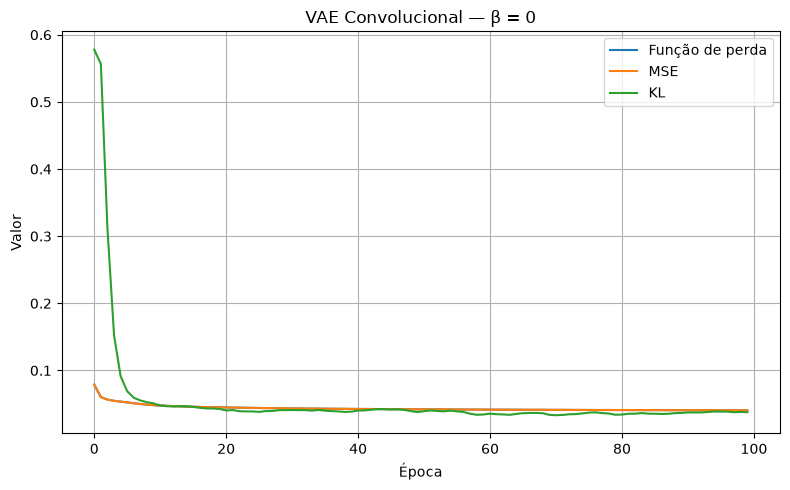

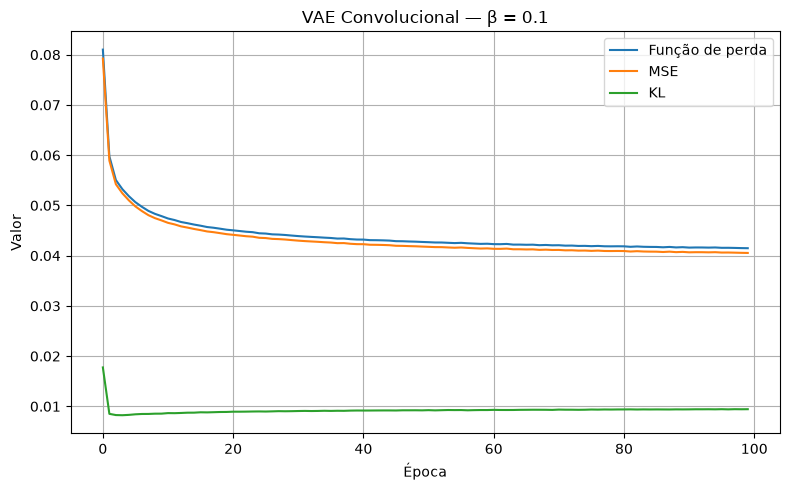

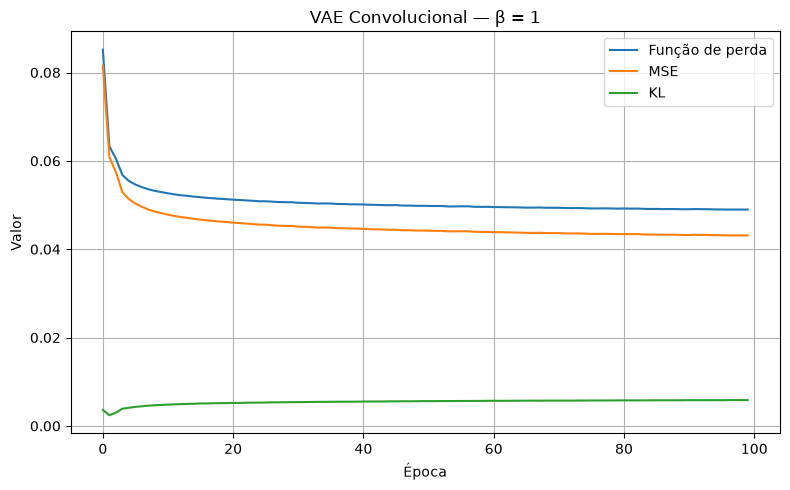

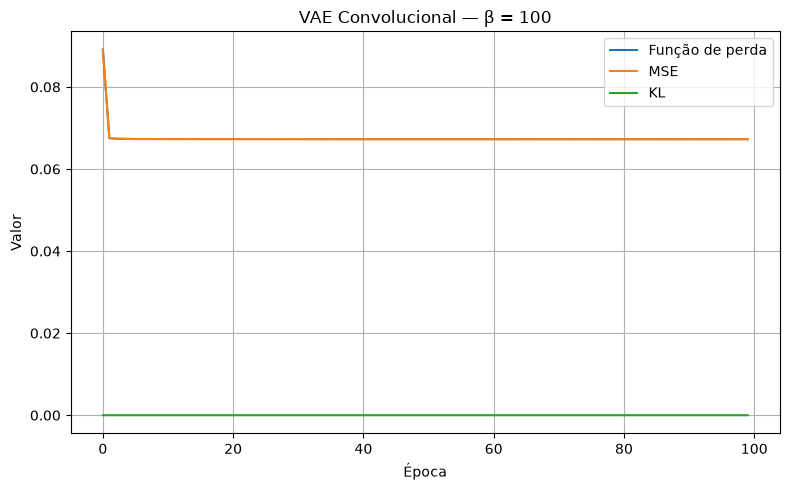

In [52]:
for beta in BETAS:
    hist_loss, hist_mse, hist_kl = historicos[beta]

    curvas_de_treinamento_adaptado(
        hist_loss,
        hist_mse,
        hist_kl,
        titulo=f"VAE Convolucional — β = {beta}"
    )

In [53]:
import pandas as pd

resultados = []

for beta in BETAS:
    hist_loss, hist_mse, hist_kl = historicos[beta]

    resultados.append({
        "β": beta,
        "MSE": hist_mse[-1],
        "KL": hist_kl[-1]
    })

df_resultados = pd.DataFrame(resultados)

display(df_resultados.round(6))

,β,MSE,KL
0,0.0,0.040593,0.037872
1,0.1,0.040538,0.009435
2,1.0,0.043134,0.005844
3,100.0,0.067269,0.000000


### 5. Reconstruções

Para cada experimento, mostre as reconstruções das 10 primeiras imagens de teste com `mostrar_reconstrucoes(modelo, test_dl, quantidade_imagens=10)`, como no código do laboratório, identificando cada figura com o valor de $\beta$. Como `test_dl` não embaralha os dados, as mesmas 10 imagens aparecem em todas as figuras, o que permite compará-las diretamente.

In [54]:
def mostrar_reconstrucoes_adaptado(modelo, carregador_teste, quantidade_imagens=10, titulo=None):
    """Exibe uma imagem original de cada categoria e sua reconstrução."""

    modelo.eval()

    imagens_selecionadas = []
    categorias = set()

    # Seleciona uma imagem de cada categoria
    for imagens, rotulos in carregador_teste:
        for imagem, rotulo in zip(imagens, rotulos):
            categoria = rotulo.item()

            if categoria not in categorias:
                imagens_selecionadas.append((categoria, imagem))
                categorias.add(categoria)

            if len(imagens_selecionadas) >= quantidade_imagens:
                break

        if len(imagens_selecionadas) >= quantidade_imagens:
            break

    # Ordena as imagens pela categoria
    imagens_selecionadas.sort(key=lambda item: item[0])

    rotulos = [categoria for categoria, _ in imagens_selecionadas]
    imagens = torch.stack([imagem for _, imagem in imagens_selecionadas]).to(DISPOSITIVO)

    # Reconstrói as imagens selecionadas
    with torch.no_grad():
        reconstrucoes, _, _ = modelo(imagens)

    plt.figure(figsize=(quantidade_imagens * 1.5, 3.5))

    if titulo is not None:
        plt.suptitle(titulo)

    for indice in range(len(imagens_selecionadas)):

        # Linha superior: imagens originais
        plt.subplot(2, quantidade_imagens, indice + 1)
        plt.imshow(imagens[indice].cpu().squeeze(), cmap="binary")
        plt.title(f"{rotulos[indice]}")
        plt.axis("off")

        # Linha inferior: imagens reconstruídas
        plt.subplot(2, quantidade_imagens, quantidade_imagens + indice + 1)
        plt.imshow(reconstrucoes[indice].cpu().squeeze(), cmap="binary")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

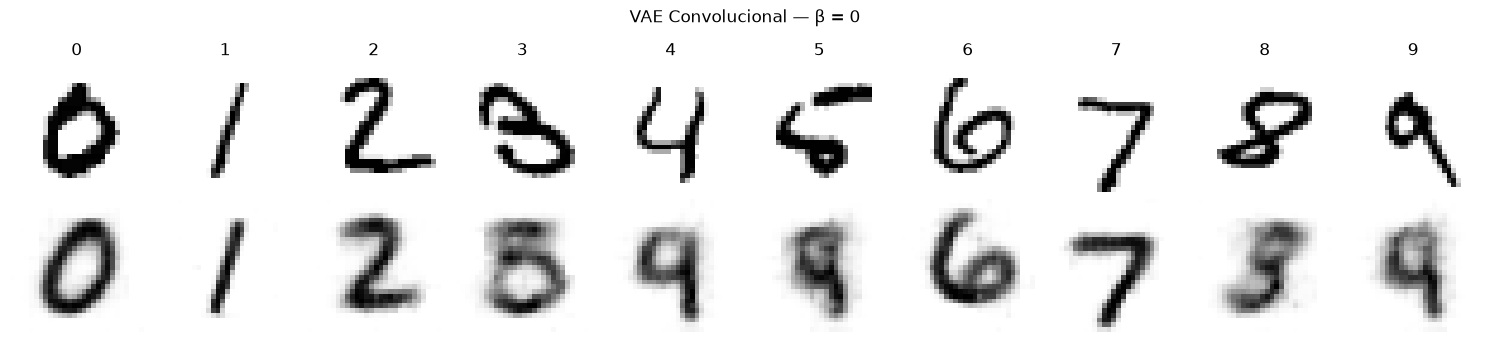

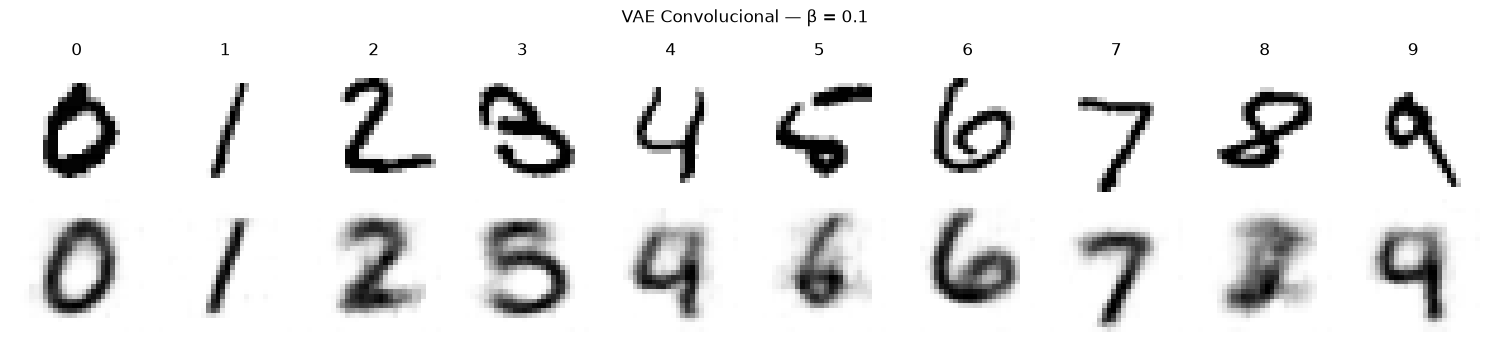

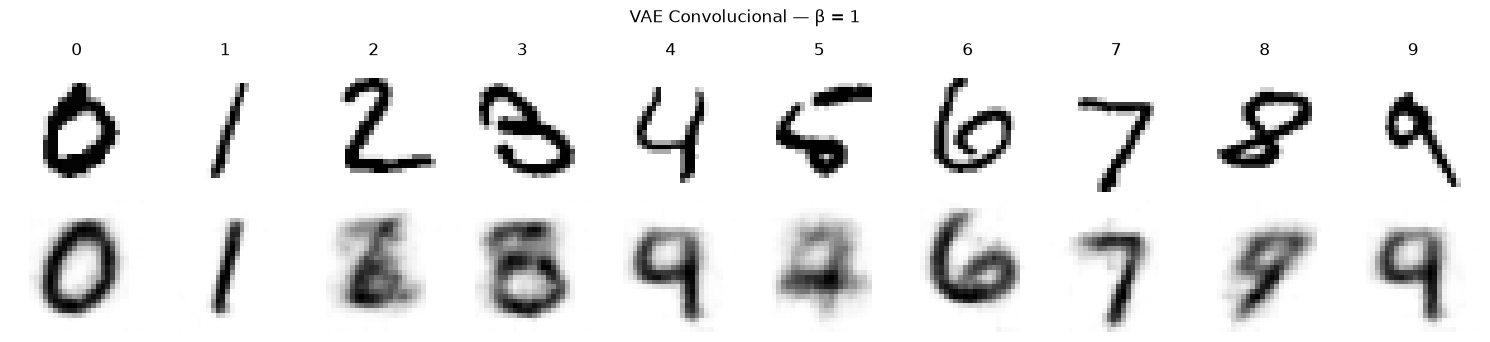

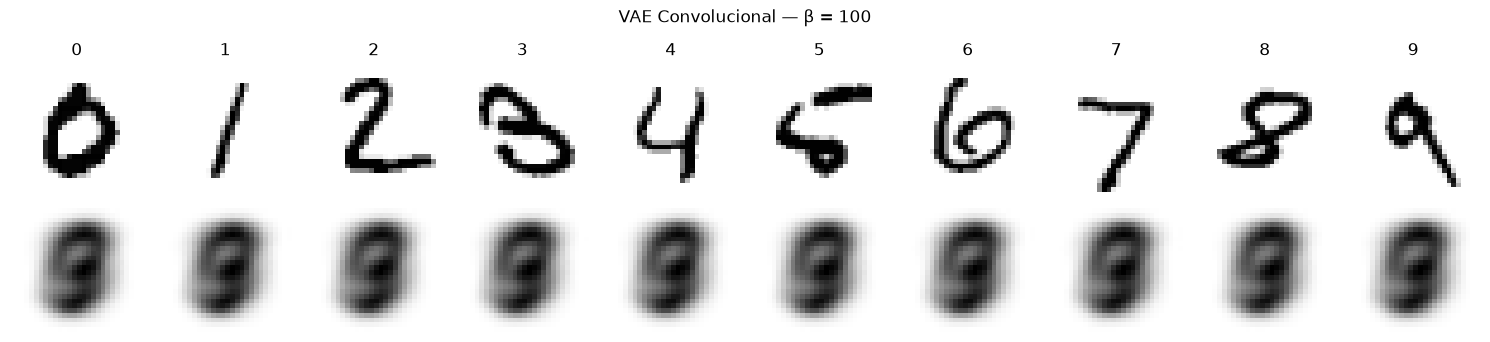

In [55]:
for beta in BETAS:
    mostrar_reconstrucoes_adaptado(
        modelos[beta],
        test_dl,
        quantidade_imagens=10,
        titulo=f"VAE Convolucional — β = {beta}"
    )

#### Resposta

### 6. Espaço latente 2D

Para cada experimento, plote as médias $\mu$ das imagens de teste no espaço latente com `visualizar_espaco_latente(modelo, test_dl)` e a grade de imagens decodificadas com `visualizar_grade_latente(modelo.decodificador, tamanho_grade=25)`, como no código do laboratório, identificando cada figura com o valor de $\beta$.

#### Resposta

In [56]:
def visualizar_espaco_latente_adaptado(modelo, carregador_dados, titulo=None):
    """Projeta as médias μ no espaço latente 2D, coloridas por classe, com o contorno de 99% da priori."""

    modelo.eval()
    vetores_latentes = []
    rotulos = []

    with torch.no_grad():
        for imagens, y in carregador_dados:
            imagens = imagens.to(DISPOSITIVO)
            media, _, _ = modelo.codificador(imagens)
            vetores_latentes.append(media.cpu().numpy())
            rotulos.append(y.cpu().numpy())

    pontos_z = np.concatenate(vetores_latentes)
    classes = np.concatenate(rotulos)

    plt.figure(figsize=(8, 6))

    grafico = plt.scatter(
        pontos_z[:, 0],
        pontos_z[:, 1],
        c=classes,
        cmap="tab10",
        s=10,
        alpha=0.7,
        vmin=-0.5,
        vmax=9.5
    )

    raio_99 = np.sqrt(-2 * np.log(1 - 0.99))
    angulos = np.linspace(0, 2 * np.pi, 200)

    plt.plot(
        raio_99 * np.cos(angulos),
        raio_99 * np.sin(angulos),
        "k--",
        label=r"$99$% de $\mathcal{N}(0, I)$"
    )

    plt.gca().set_aspect("equal", adjustable="datalim")
    plt.legend(loc="upper right")
    plt.colorbar(grafico, ticks=range(10), label="Classe")
    plt.title(titulo if titulo is not None else r"Projeção de $\mu$ no espaço latente (2D)")
    plt.xlabel("z[0]")
    plt.ylabel("z[1]")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [57]:
def visualizar_grade_latente_adaptado(decodificador, tamanho_grade=20, titulo=None):
    """Gera uma grade de imagens decodificadas a partir de pontos regulares no espaço latente 2D."""

    assert tamanho_grade > 1, "Tamanho da grade deve ser maior que 1."

    decodificador.eval()

    eixo = norm.ppf(np.linspace(0.01, 0.99, tamanho_grade))

    linhas_imagem = []

    with torch.no_grad():
        for valor_y in eixo:
            linha_atual = []

            for valor_x in eixo:
                ponto_latente = torch.tensor(
                    [[valor_x, valor_y]],
                    dtype=torch.float32,
                    device=DISPOSITIVO
                )

                imagem = decodificador(ponto_latente).cpu().squeeze().numpy()
                linha_atual.append(imagem)

            linhas_imagem.append(np.concatenate(linha_atual, axis=1))

    imagem_grade = np.concatenate(linhas_imagem, axis=0)

    plt.figure(figsize=(8, 8))
    plt.imshow(imagem_grade, cmap="binary")
    plt.axis("off")
    plt.title(titulo if titulo is not None else "Reconstruções em grade no espaço latente 2D")
    plt.tight_layout()
    plt.show()

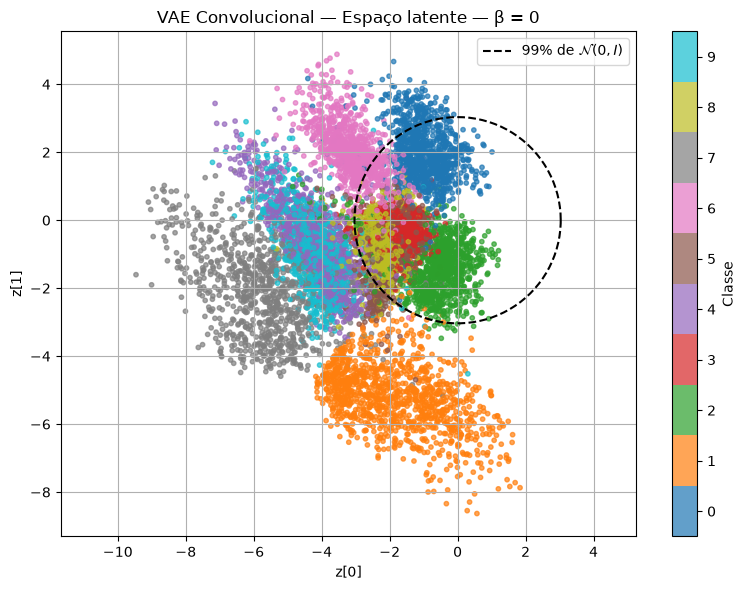

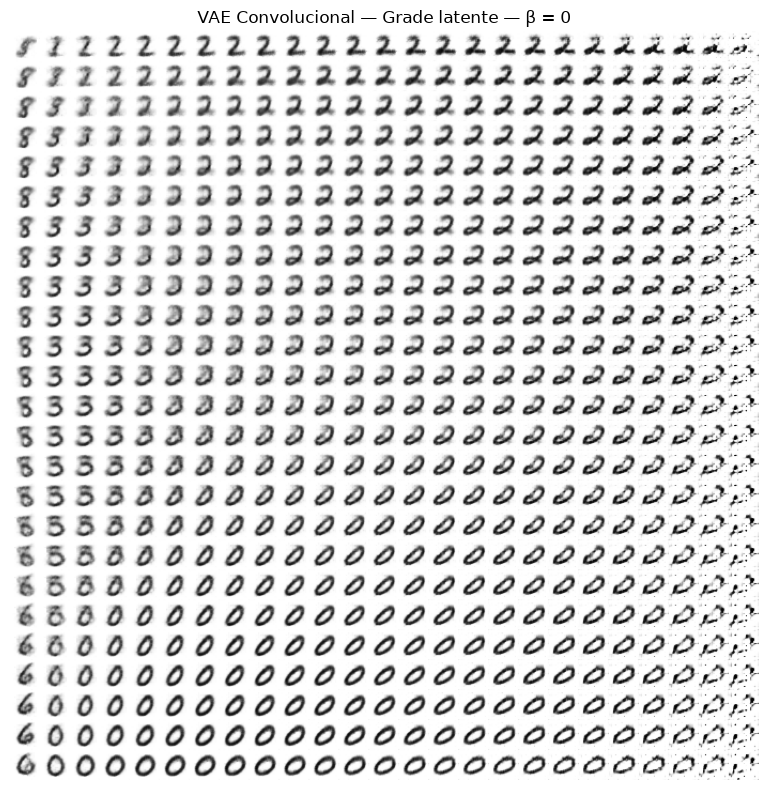

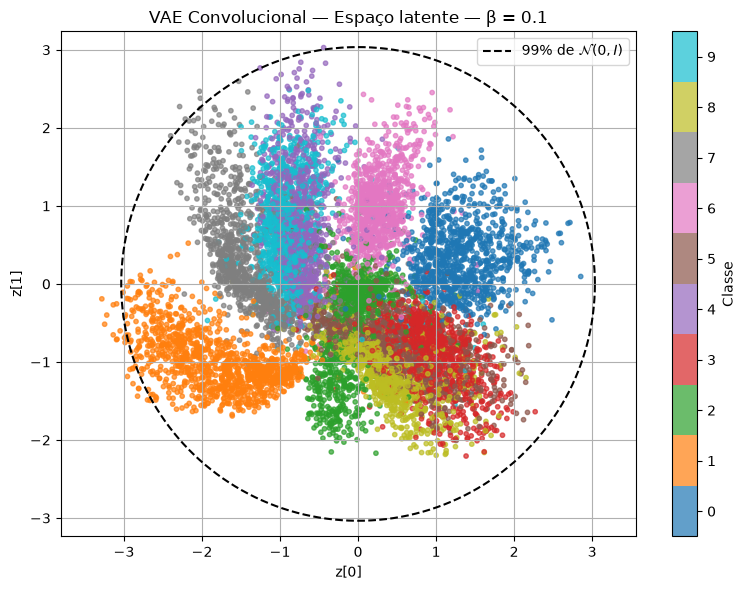

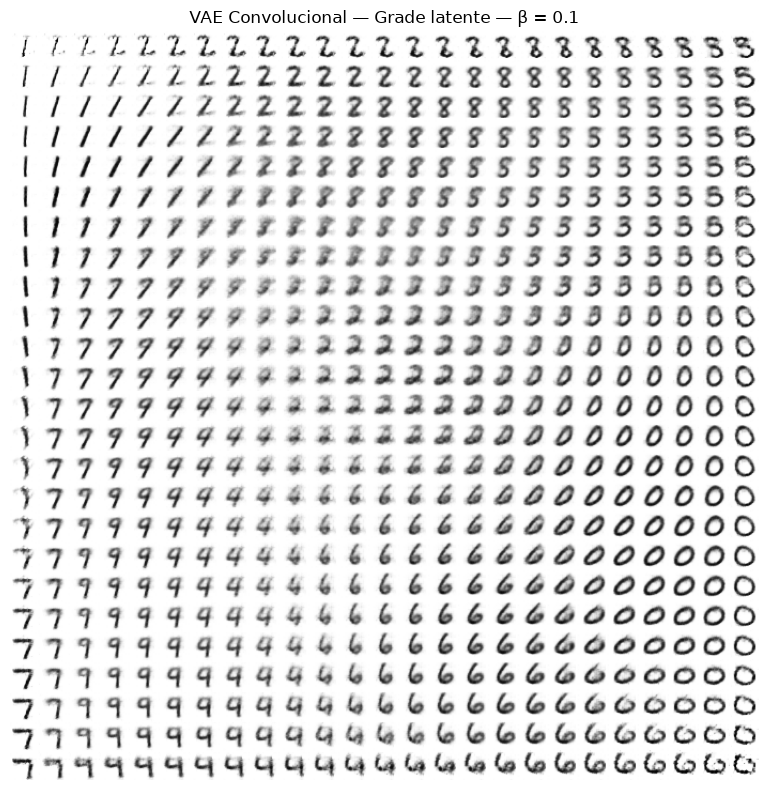

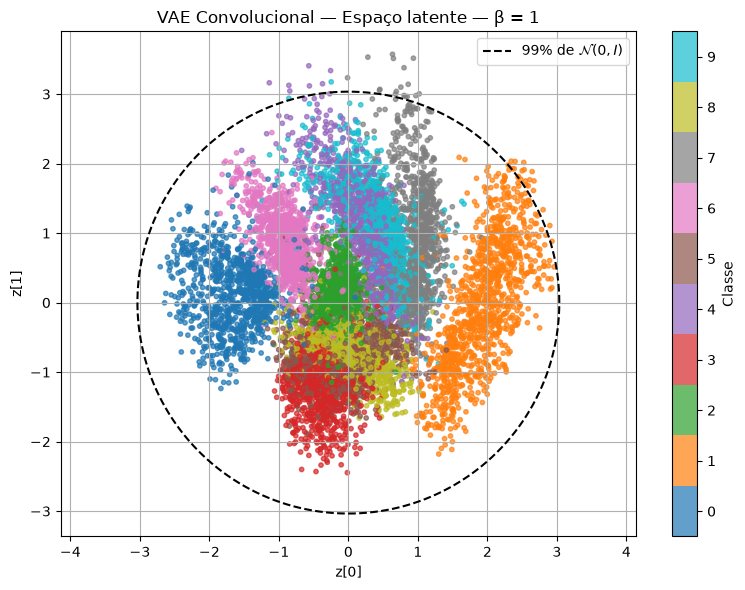

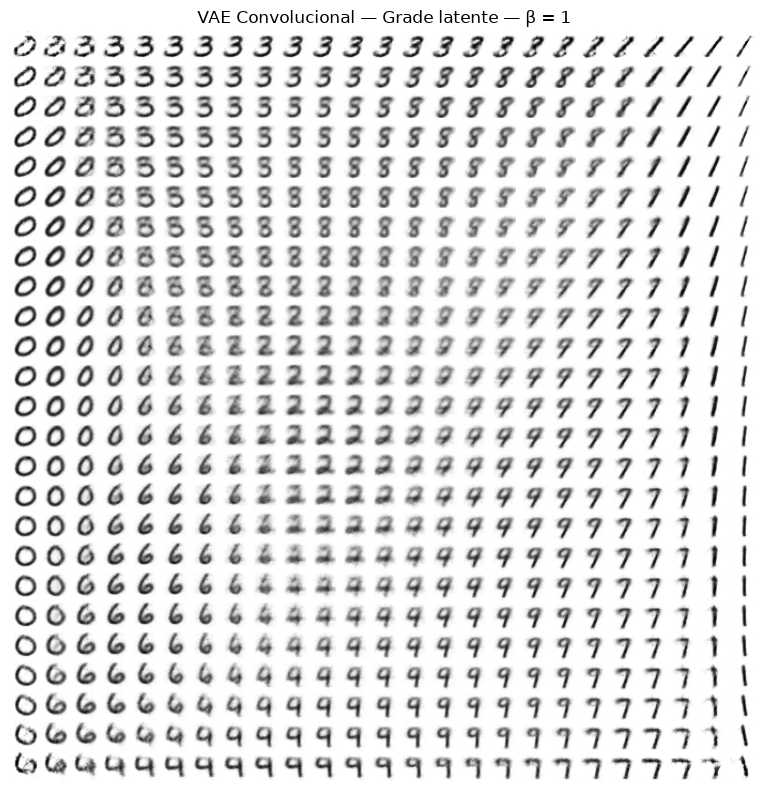

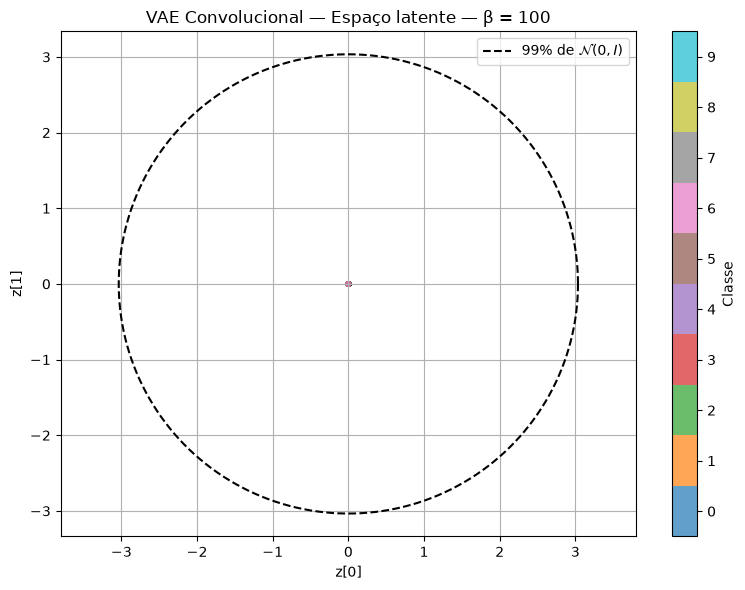

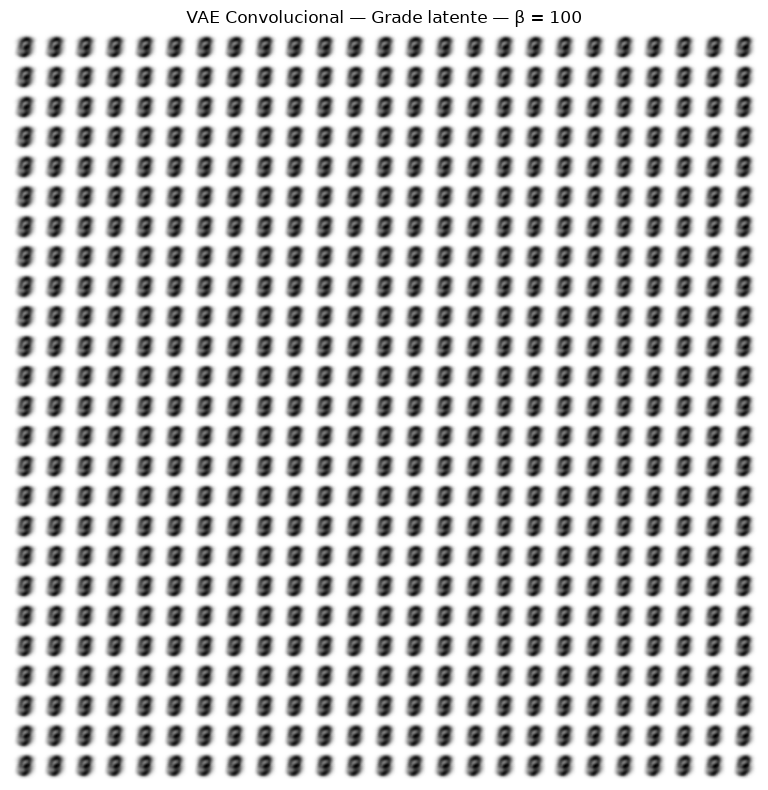

In [58]:
for beta in BETAS:
    modelo = modelos[beta]

    visualizar_espaco_latente_adaptado(
        modelo,
        test_dl,
        titulo=f"VAE Convolucional — Espaço latente — β = {beta}"
    )

    visualizar_grade_latente_adaptado(
        modelo.decodificador,
        tamanho_grade=25,
        titulo=f"VAE Convolucional — Grade latente — β = {beta}"
    )

### 7. Amostras geradas

Para cada experimento, gere 21 amostras a partir de vetores latentes aleatórios $z \sim \mathcal{N}(0, I)$ com `gerar_amostras_aleatorias(modelo, DIMENSAO_LATENTE_DENSO, total_imagens=21, colunas=7)`, como no código do laboratório, identificando cada figura com o valor de $\beta$. Chame `torch.manual_seed(42)` imediatamente antes de cada chamada, para que os quatro modelos decodifiquem os mesmos vetores latentes e as diferenças entre as figuras se devam apenas a $\beta$.

#### Resposta

In [61]:
def gerar_amostras_aleatorias_adaptado(modelo, dimensao_latente, total_imagens, colunas, titulo=None):
    """Gera novas amostras a partir de vetores latentes aleatórios (z ~ N(0,1))."""

    modelo.eval()

    with torch.no_grad():
        vetores_latentes = torch.randn(
            total_imagens,
            dimensao_latente,
            device=DISPOSITIVO
        )
        imagens = modelo.decodificador(vetores_latentes).cpu().numpy()

    linhas = (total_imagens - 1) // colunas + 1
    plt.figure(figsize=(colunas, linhas + 0.5))

    if titulo is not None:
        plt.suptitle(titulo)

    for indice, imagem in enumerate(imagens):
        plt.subplot(linhas, colunas, indice + 1)
        plt.imshow(imagem.squeeze(), cmap="binary")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

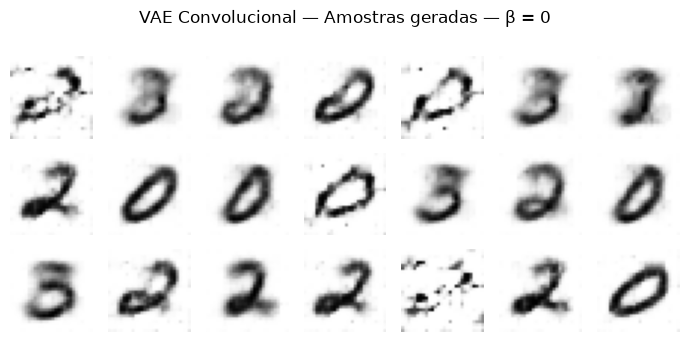

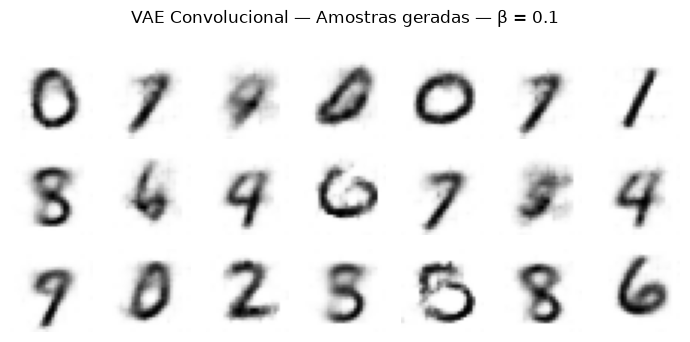

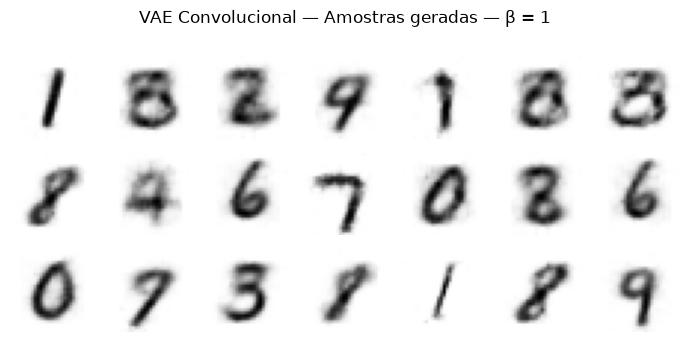

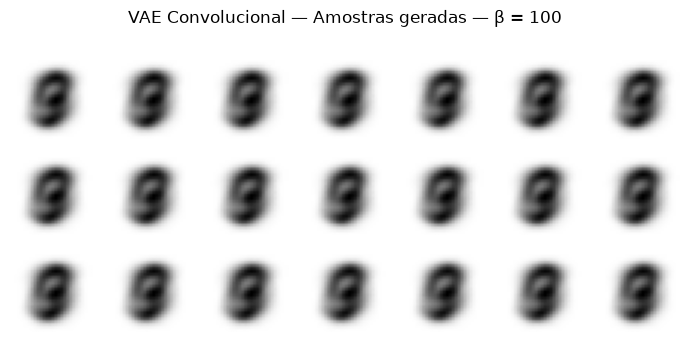

In [62]:
for beta in BETAS:
    torch.manual_seed(42)

    gerar_amostras_aleatorias_adaptado(
        modelos[beta],
        DIMENSAO_LATENTE_DENSO,
        total_imagens=21,
        colunas=7,
        titulo=f"VAE Convolucional — Amostras geradas — β = {beta}"
    )

## Análise

Responda a cada pergunta a partir da inspeção visual das figuras dos itens 4 a 7, indicando em quais itens a resposta se apoia. Explique o comportamento observado a partir do papel de $\beta$ na função de perda; não é preciso citar valores numéricos.

**(a)** Qual é o papel de $\beta$ na função de perda? O que se espera que aconteça com o termo de reconstrução (MSE) e com o de regularização (KL) quando $\beta$ é muito pequeno (no limite, $\beta = 0$) e quando é grande demais, e por quê? As curvas do item 4 confirmam essa expectativa?

**(b)** Como $\beta$ afeta a nitidez das reconstruções? Há indícios de colapso da posterior [*posterior collapse*], isto é, de reconstruções que quase não dependem da imagem de entrada?

**(c)** Como $\beta$ afeta a organização do espaço latente 2D? Em cada experimento, como a região ocupada pelas médias $\mu$ se compara à região delimitada pela linha tracejada do item 6? Dígitos visualmente parecidos ficam próximos?

**(d)** Para qual valor de $\beta$ as amostras geradas a partir de $z \sim \mathcal{N}(0, I)$ mais se parecem com dígitos e são mais variadas? Relacione a resposta ao espaço latente do item 6: por que um modelo que reconstrói bem pode gerar amostras ruins?

### Resposta (a)

### Resposta (b)

### Resposta (c)

### Resposta (d)